# House Price Analysis: King County, Washington

**Business question:** What drives house prices, and how accurately can we estimate a home's price from its characteristics?

**Data:** 21,613 house sales in King County, Washington (which includes Seattle), from May 2014 to May 2015. Prices are in US dollars.

## Summary of findings

1. **Location sets the price per square foot.** The median price per sq ft ranges almost 4× across zipcodes, from about \$145 to \$565.
2. **Size and build quality drive the rest.** Living area and construction grade are the strongest single predictors; each step up in grade adds roughly 30–40% to the median price.
3. **Waterfront homes sell for about 3× the median** (\$1.4M vs \$450K), though only 163 sales are waterfront.
4. **Prices were flat over the 13 months.** The monthly median moved between about \$425K and \$477K, with no clear trend.
5. **A gradient-boosted model estimates prices with a typical error of about 8%** (median absolute percentage error), explaining about 90% of the variation in price (R²) on unseen sales. A linear model on raw prices, as in my first version, explained about 70%, with a typical error of about 19%.

**Most useful lesson:** treating **zipcode** as a category, and modelling prices and sizes on a **log scale**, took the simple linear model from 0.70 to 0.87 R². That was a bigger gain than switching to a more complex algorithm.

## 1. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder, FunctionTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error

sns.set_theme(style="whitegrid")
os.makedirs("images", exist_ok=True)
RANDOM_STATE = 42
TEAL, AMBER, GREY = "#1F5F6B", "#B87A12", "#C9D4DC"
dollars = mtick.FuncFormatter(lambda v, _: f"${v/1e6:.1f}M" if v >= 1e6 else f"${v/1e3:.0f}K")

## 2. Load the data

In [2]:
df = pd.read_csv("house_price.csv")
df["date"] = pd.to_datetime(df["date"].str[:8], format="%Y%m%d")
print(df.shape)
print("Sales from", df["date"].min().date(), "to", df["date"].max().date())
df.head()

(21613, 21)
Sales from 2014-05-02 to 2015-05-27


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,2014-10-13,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,2014-12-09,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,2015-02-25,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,2014-12-09,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,2015-02-18,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [3]:
df.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
id,21613.0,4580301520.864988,1000102.0,2123049194.0,3904930410.0,7308900445.0,9900000190.0,2876565571.312057
date,21613,2014-10-29 04:38:01.959931,2014-05-02 00:00:00,2014-07-22 00:00:00,2014-10-16 00:00:00,2015-02-17 00:00:00,2015-05-27 00:00:00,NaN
price,21613.0,540088.141767,75000.0,321950.0,450000.0,645000.0,7700000.0,367127.196483
bedrooms,21613.0,3.370842,0.0,3.0,3.0,4.0,33.0,0.930062
bathrooms,21613.0,2.114757,0.0,1.75,2.25,2.5,8.0,0.770163
sqft_living,21613.0,2079.899736,290.0,1427.0,1910.0,2550.0,13540.0,918.440897
sqft_lot,21613.0,15106.967566,520.0,5040.0,7618.0,10688.0,1651359.0,41420.511515
floors,21613.0,1.494309,1.0,1.0,1.5,2.0,3.5,0.539989
waterfront,21613.0,0.007542,0.0,0.0,0.0,0.0,1.0,0.086517
view,21613.0,0.234303,0.0,0.0,0.0,0.0,4.0,0.766318


## 3. Data quality

No missing values and no duplicate rows. The checks below look for values that are possible in the file but not in reality.

In [4]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Houses sold more than once:", df["id"].duplicated().sum())
print("Zero bedrooms:", (df["bedrooms"] == 0).sum(), "| Zero bathrooms:", (df["bathrooms"] == 0).sum())
df.loc[df["bedrooms"] >= 10, ["price", "bedrooms", "bathrooms", "sqft_living", "sqft_lot"]]

Missing values: 0
Duplicate rows: 0
Houses sold more than once: 177
Zero bedrooms: 13 | Zero bathrooms: 10


,price,bedrooms,bathrooms,sqft_living,sqft_lot
8757,520000.0,11,3.00,3000,4960
13314,1148000.0,10,5.25,4590,10920
15161,650000.0,10,2.00,3610,11914
15870,640000.0,33,1.75,1620,6000
19254,660000.0,10,3.00,2920,3745


- **33 bedrooms in 1,620 sq ft** is almost certainly a typing error for 3, since the size and price match a 3-bedroom house. I correct it to 3. The 11-bedroom house (3,000 sq ft) is unusual but possible, so I keep it.
- **Zero bedrooms or bathrooms** (16 sales) could be studios or data gaps. They are a tiny share, so I keep them.
- **177 homes were sold twice** in the period. These are genuine resales, not duplicates, so I keep both sales.
- `yr_renovated = 0` means "never renovated", not the year 0. I convert it to a yes/no flag and a "years since built or renovated" feature, so it isn't read as a number.

In [5]:
df.loc[df["bedrooms"] == 33, "bedrooms"] = 3

df["sale_year"] = df["date"].dt.year
df["house_age"] = (df["sale_year"] - df["yr_built"]).clip(lower=0)
df["renovated"] = (df["yr_renovated"] > 0).astype(int)
last_work = np.where(df["yr_renovated"] > 0, df["yr_renovated"], df["yr_built"])
df["years_since_work"] = (df["sale_year"] - last_work).clip(lower=0)
df["has_basement"] = (df["sqft_basement"] > 0).astype(int)
df["price_per_sqft"] = df["price"] / df["sqft_living"]
df["zipcode"] = df["zipcode"].astype(str)

## 4. What drives price?

### 4.1 Price is right-skewed

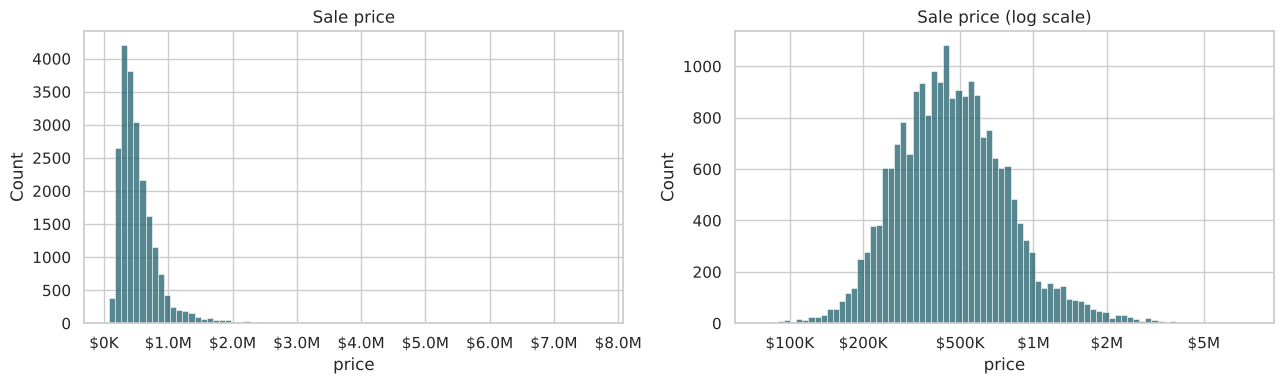

Median $450,000 | Mean $540,088 | Max $7,700,000


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["price"], bins=80, ax=axes[0], color=TEAL)
axes[0].xaxis.set_major_formatter(dollars)
axes[0].set_title("Sale price")
sns.histplot(np.log10(df["price"]), bins=80, ax=axes[1], color=TEAL)
axes[1].set_title("Sale price (log scale)")
axes[1].set_xticks(np.log10([1e5, 2e5, 5e5, 1e6, 2e6, 5e6]))
axes[1].set_xticklabels(["$100K", "$200K", "$500K", "$1M", "$2M", "$5M"])
plt.tight_layout()
plt.show()
print(f"Median ${df['price'].median():,.0f} | Mean ${df['price'].mean():,.0f} | Max ${df['price'].max():,.0f}")

The mean (\$540K) sits well above the median (\$450K) because a few very expensive homes pull it up. On a log scale, prices are roughly bell-shaped. I use the **median** to describe typical prices, and model the **log of price** so the model treats a 10% error the same on a \$300K home as on a \$3M home.

### 4.2 Size, grade, waterfront and view

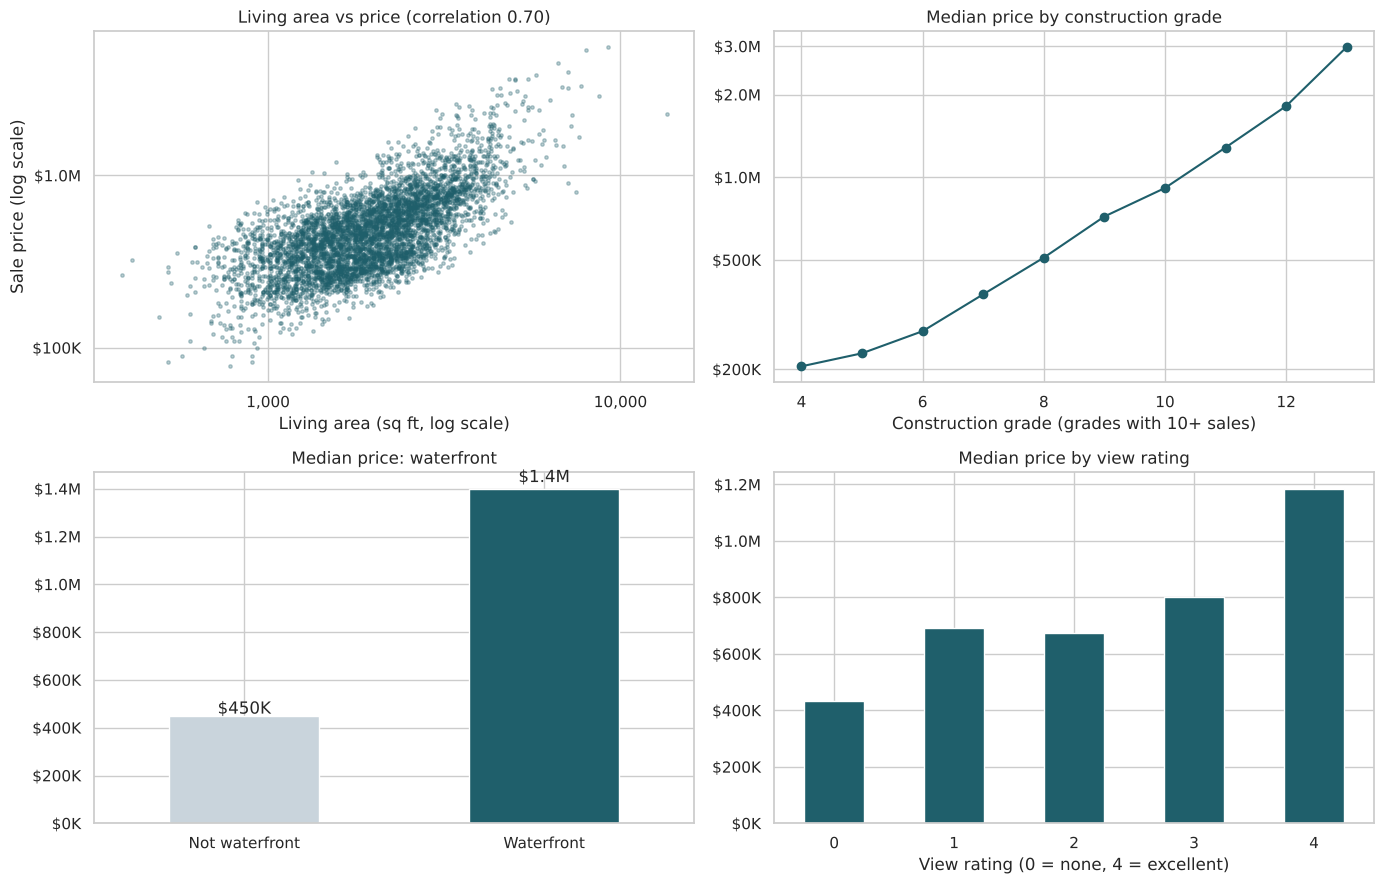

          median  count
grade                  
4       205000.0     29
5       228700.0    242
6       275276.5   2038
7       375000.0   8981
8       510000.0   6068
9       720000.0   2615
10      914327.0   1134
11     1284000.0    399
12     1817500.0     90
13     2983000.0     13


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sample = df.sample(5000, random_state=RANDOM_STATE)
axes[0, 0].scatter(sample["sqft_living"], sample["price"], s=6, alpha=0.3, color=TEAL)
axes[0, 0].set_xscale("log"); axes[0, 0].set_yscale("log")
axes[0, 0].yaxis.set_major_formatter(dollars)
axes[0, 0].set_xlabel("Living area (sq ft, log scale)")
axes[0, 0].set_ylabel("Sale price (log scale)")
axes[0, 0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[0, 0].set_title(f"Living area vs price (correlation {df['price'].corr(df['sqft_living']):.2f})")

grade = df.groupby("grade")["price"].agg(["median", "count"])
grade = grade[grade["count"] >= 10]
axes[0, 1].plot(grade.index, grade["median"], marker="o", color=TEAL)
axes[0, 1].set_yscale("log")
axes[0, 1].yaxis.set_major_locator(mtick.FixedLocator([2e5, 5e5, 1e6, 2e6, 3e6]))
axes[0, 1].yaxis.set_minor_formatter(mtick.NullFormatter())
axes[0, 1].yaxis.set_major_formatter(dollars)
axes[0, 1].set_xlabel("Construction grade (grades with 10+ sales)")
axes[0, 1].set_title("Median price by construction grade")

wf = df.groupby("waterfront")["price"].median().rename({0: "Not waterfront", 1: "Waterfront"})
wf.plot.bar(ax=axes[1, 0], color=[GREY, TEAL], rot=0)
axes[1, 0].yaxis.set_major_formatter(dollars)
axes[1, 0].set_xlabel("")
axes[1, 0].set_title("Median price: waterfront")
for i, v in enumerate(wf):
    axes[1, 0].text(i, v * 1.02, dollars(v), ha="center")

view = df.groupby("view")["price"].median()
view.plot.bar(ax=axes[1, 1], color=TEAL, rot=0)
axes[1, 1].yaxis.set_major_formatter(dollars)
axes[1, 1].set_xlabel("View rating (0 = none, 4 = excellent)")
axes[1, 1].set_title("Median price by view rating")

plt.tight_layout()
plt.savefig("images/price_drivers.png", dpi=150, bbox_inches="tight")
plt.show()
print(grade)

- **Living area** has the strongest correlation with price (0.70).
- **Grade** (the county's rating of construction quality, 1–13) shows a steady climb: each step adds roughly 30–40% to the median price.
- **Waterfront** homes have about 3× the median price, and better **views** command a steady premium.

### 4.3 Location

70 zipcodes. Median price per sq ft ranges from $145 to $565 (3.9x)


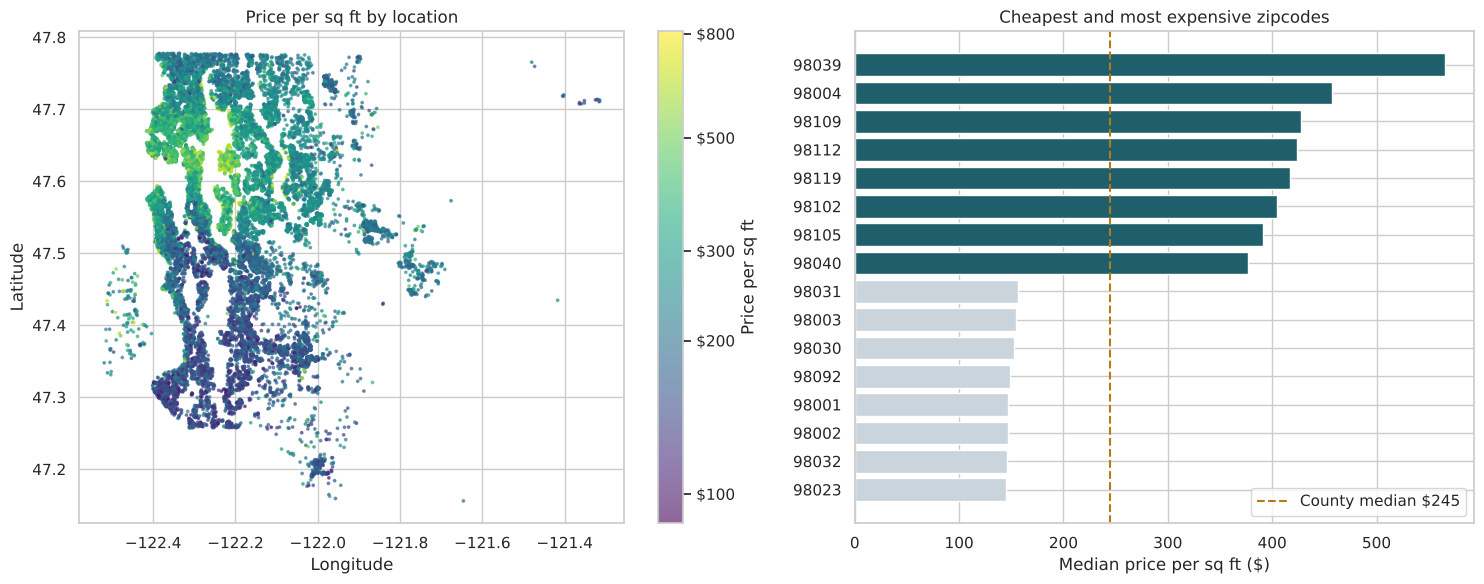

In [8]:
zip_stats = (df.groupby("zipcode")
               .agg(sales=("price", "size"),
                    median_price=("price", "median"),
                    median_price_per_sqft=("price_per_sqft", "median"),
                    lat=("lat", "mean"), long=("long", "mean"))
               .sort_values("median_price_per_sqft"))
print(f"{len(zip_stats)} zipcodes. Median price per sq ft ranges from "
      f"${zip_stats['median_price_per_sqft'].min():.0f} to ${zip_stats['median_price_per_sqft'].max():.0f} "
      f"({zip_stats['median_price_per_sqft'].max() / zip_stats['median_price_per_sqft'].min():.1f}x)")

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.1, 1]})
sc = axes[0].scatter(df["long"], df["lat"], c=np.log10(df["price_per_sqft"]), cmap="viridis", s=3, alpha=0.6)
cbar = fig.colorbar(sc, ax=axes[0])
ticks = [100, 200, 300, 500, 800]
cbar.set_ticks(np.log10(ticks)); cbar.set_ticklabels([f"${t}" for t in ticks])
cbar.set_label("Price per sq ft")
axes[0].set_xlabel("Longitude"); axes[0].set_ylabel("Latitude")
axes[0].set_title("Price per sq ft by location")

top_bottom = pd.concat([zip_stats.head(8), zip_stats.tail(8)])
colors = [GREY] * 8 + [TEAL] * 8
axes[1].barh(top_bottom.index, top_bottom["median_price_per_sqft"], color=colors)
axes[1].axvline(df["price_per_sqft"].median(), color=AMBER, linestyle="--", label=f"County median ${df['price_per_sqft'].median():.0f}")
axes[1].set_xlabel("Median price per sq ft ($)")
axes[1].set_title("Cheapest and most expensive zipcodes")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.savefig("images/price_by_location.png", dpi=150, bbox_inches="tight")
plt.show()

Location is the biggest factor that size and grade don't capture. Homes in the north and east of Seattle (around Bellevue, Mercer Island and Medina, zipcodes 98004 and 98039) cost 3–4× more per square foot than homes in the south of the county. That is why zipcode must be treated as a **category**: as a plain number, the model would wrongly assume 98039 is "more" than 98004 in some smooth way.

### 4.4 Correlation

In [9]:
num_cols = ["price", "sqft_living", "grade", "sqft_above", "sqft_living15", "bathrooms", "view", "sqft_basement",
            "bedrooms", "lat", "waterfront", "floors", "renovated", "sqft_lot", "condition", "house_age"]
corr = df[num_cols].corr(method="spearman")
corr["price"].drop("price").sort_values(ascending=False).round(2)

grade            0.66
sqft_living      0.64
sqft_living15    0.57
sqft_above       0.54
bathrooms        0.50
lat              0.46
bedrooms         0.34
floors           0.32
view             0.29
sqft_basement    0.25
waterfront       0.12
renovated        0.10
sqft_lot         0.07
condition        0.02
house_age       -0.10
Name: price, dtype: float64

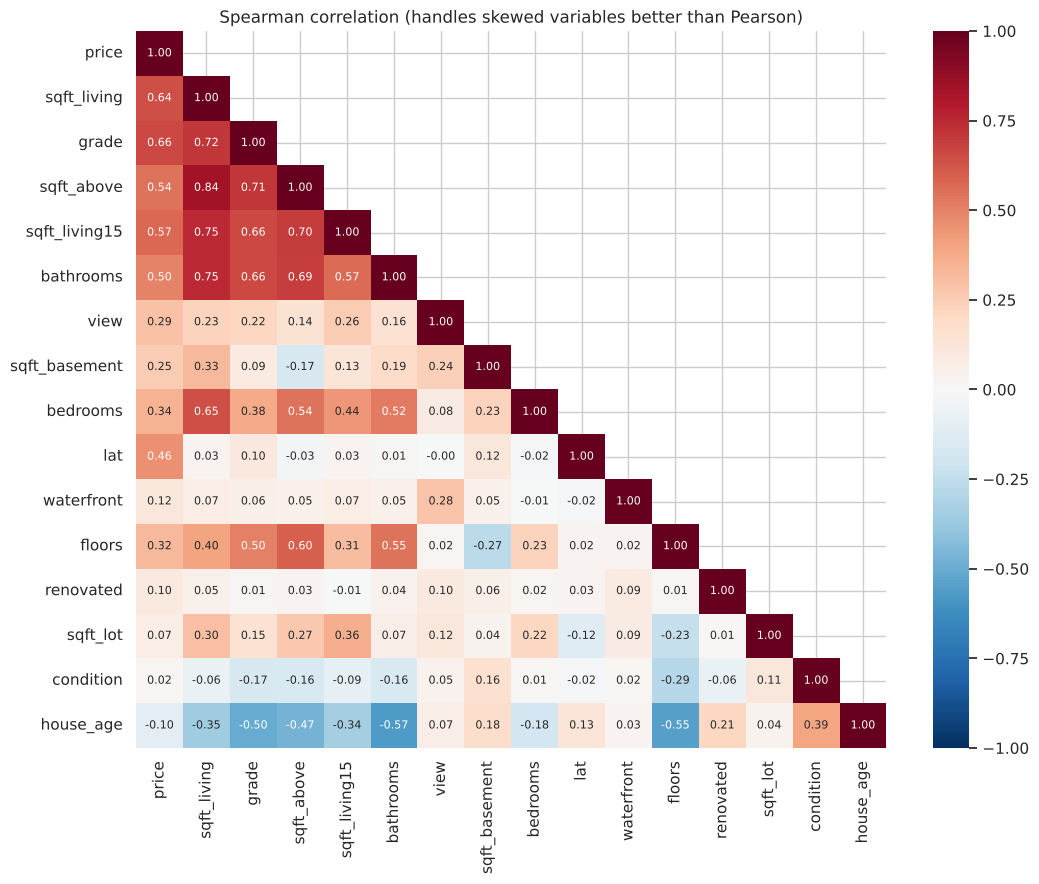

In [10]:
plt.figure(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, annot_kws={"size": 8})
plt.title("Spearman correlation (handles skewed variables better than Pearson)")
plt.tight_layout()
plt.show()

Living area, grade, above-ground area and neighbours' living area (`sqft_living15`) are all strongly correlated with price, and with each other. Because they overlap so much, their individual effects in a linear model should be read with care.

### 4.5 Did prices change over time?

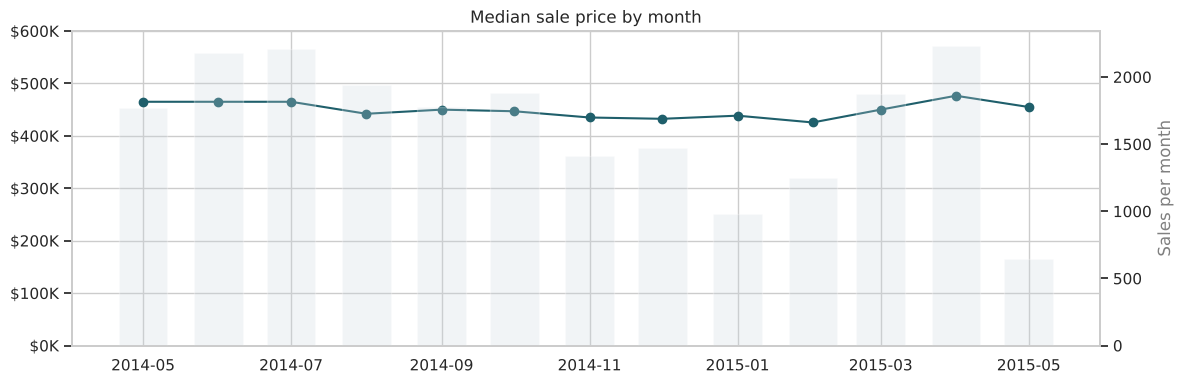

,median,size
date,,
2014-05-01,465000.0,1768
2014-06-01,465000.0,2180
2014-07-01,465000.0,2211
2014-08-01,442100.0,1940
2014-09-01,450000.0,1774
2014-10-01,446900.0,1878
2014-11-01,435000.0,1411
2014-12-01,432500.0,1471
2015-01-01,438500.0,978


In [11]:
monthly = df.set_index("date").resample("MS")["price"].agg(["median", "size"])
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly.index, monthly["median"], marker="o", color=TEAL)
ax.set_ylim(0, 600_000)
ax.yaxis.set_major_formatter(dollars)
ax.set_title("Median sale price by month")
ax2 = ax.twinx()
ax2.bar(monthly.index, monthly["size"], width=20, alpha=0.25, color=GREY)
ax2.set_ylabel("Sales per month", color="grey")
ax2.grid(False)
plt.tight_layout()
plt.show()
monthly

On a scale starting at zero, the monthly median price is flat at around \$425K–\$477K. The data covers only 13 months, so comparing "2014 vs 2015" compares eight months with five; the apparent drop in sales in 2015 is simply because the data stops in May. There is a mild seasonal pattern (more sales in spring and summer), but no meaningful price trend.

## 5. Estimating price

**Setup**
- **Target:** log of price. Errors are reported back in dollars and as a percentage.
- **For the linear model, size features are also logged.** Price grows roughly in proportion to size, so a log-log relationship fits better. Without it, the model predicted \$13M for a \$2.3M mansion with 13,540 sq ft.
- **Split first:** 80% training, 20% test, with all preprocessing inside pipelines fitted on training data only.
- **Features:** size, rooms, floors, waterfront, view, condition, grade, age, renovation, basement, zipcode, and latitude/longitude. I drop `id`, the sale date and the derived `price_per_sqft`, which uses the price itself.
- **Baseline:** predict the training-set median price for every house.
- **Metrics:** MAE (average error in \$), median absolute percentage error (the typical % error), and R² (share of price variation explained).

In [12]:
size = ["sqft_living", "sqft_lot", "sqft_above", "sqft_basement", "sqft_living15", "sqft_lot15"]
numeric = size + ["bedrooms", "bathrooms", "floors", "waterfront", "view", "condition", "grade",
           "house_age", "years_since_work", "renovated", "lat", "long"]
categorical = ["zipcode"]

X = df[numeric + categorical]
y = df["price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Train: {len(X_train):,} sales | Test: {len(X_test):,} sales")

log_target = dict(func=np.log, inverse_func=np.exp)

other = [c for c in numeric if c not in size]
linear_prep = ColumnTransformer([
    ("size", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                       ("scale", StandardScaler())]), size),
    ("num", StandardScaler(), other),
    ("zip", OneHotEncoder(handle_unknown="ignore"), categorical),
])
tree_prep = ColumnTransformer([
    ("num", "passthrough", numeric),
    ("zip", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical),
])

models = {
    "Baseline: median price": DummyRegressor(strategy="median"),
    "Linear Regression (my first version: raw price, zipcode as a number)":
        Pipeline([("prep", ColumnTransformer([("num", StandardScaler(), numeric + categorical)])),
                  ("model", LinearRegression())]),
    "Ridge Regression (log price and size, zipcode as category)":
        TransformedTargetRegressor(Pipeline([("prep", linear_prep), ("model", RidgeCV(alphas=np.logspace(-3, 2, 20)))]), **log_target),
    "Random Forest (log price)":
        TransformedTargetRegressor(Pipeline([("prep", tree_prep),
                                             ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE))]), **log_target),
    "Gradient Boosting (log price)":
        TransformedTargetRegressor(Pipeline([("prep", tree_prep),
                                             ("model", HistGradientBoostingRegressor(max_iter=600, learning_rate=0.05, categorical_features=[len(numeric)],
                                                                                     random_state=RANDOM_STATE))]), **log_target),
}

rows, fitted = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    pred = model.predict(X_test)
    rows.append({
        "model": name,
        "MAE ($)": mean_absolute_error(y_test, pred),
        "RMSE ($)": np.sqrt(mean_squared_error(y_test, pred)),
        "median % error": np.median(np.abs(pred - y_test) / y_test) * 100,
        "R²": r2_score(y_test, pred),
    })

scores = pd.DataFrame(rows).set_index("model")
scores.style.format({"MAE ($)": "${:,.0f}", "RMSE ($)": "${:,.0f}", "median % error": "{:.1f}%", "R²": "{:.3f}"})

Train: 17,290 sales | Test: 4,323 sales


,MAE ($),RMSE ($),median % error,R²
model,,,,
Baseline: median price,"$229,736","$401,311",34.3%,-0.065
"Linear Regression (my first version: raw price, zipcode as a number)","$127,455","$212,416",19.4%,0.702
"Ridge Regression (log price and size, zipcode as category)","$75,730","$138,342",9.8%,0.873
Random Forest (log price),"$72,265","$138,691",8.9%,0.873
Gradient Boosting (log price),"$65,017","$121,202",8.2%,0.903


**Note on terms:** R² is not "accuracy". An R² of 0.90 means the model explains 90% of the variation in price. The median % error is easier to explain to a non-technical audience: for half of all homes, the estimate is within that percentage of the actual sale price.

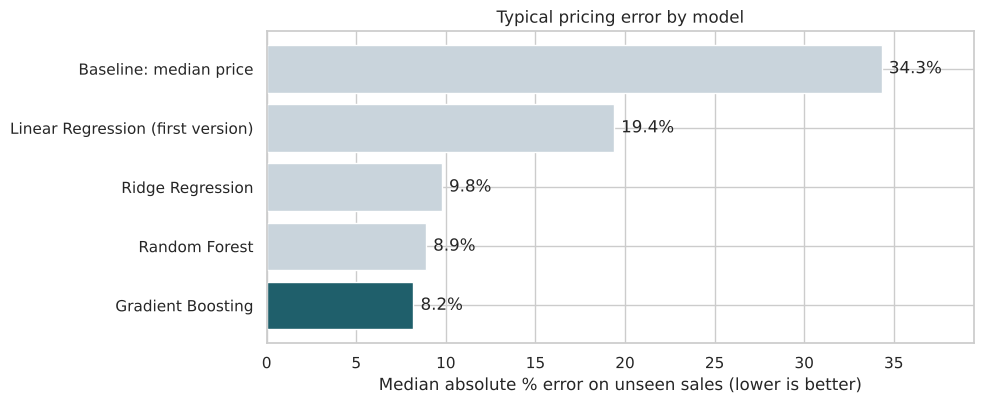

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.2))
order = scores.index[::-1]
short = {n: n.split(" (")[0] if not n.startswith("Linear") else "Linear Regression (first version)" for n in order}
vals = scores.loc[order, "median % error"]
bars = ax.barh([short[n] for n in order], vals, color=[TEAL if "Boosting" in n else GREY for n in order])
for b, v in zip(bars, vals):
    ax.text(v + 0.4, b.get_y() + b.get_height() / 2, f"{v:.1f}%", va="center")
ax.set_xlabel("Median absolute % error on unseen sales (lower is better)")
ax.set_title("Typical pricing error by model")
ax.set_xlim(0, max(vals) * 1.15)
plt.tight_layout()
plt.savefig("images/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.1 Is the result stable?

In [14]:
best_name = "Gradient Boosting (log price)"
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_r2 = cross_val_score(models[best_name], X_train, y_train, cv=cv, scoring="r2")
print("R² per fold:", np.round(cv_r2, 3))
print(f"Mean R²: {cv_r2.mean():.3f} ± {cv_r2.std():.3f}")

R² per fold: [0.891 0.899 0.886 0.86  0.904]
Mean R²: 0.888 ± 0.015


### 5.2 Where the model goes wrong

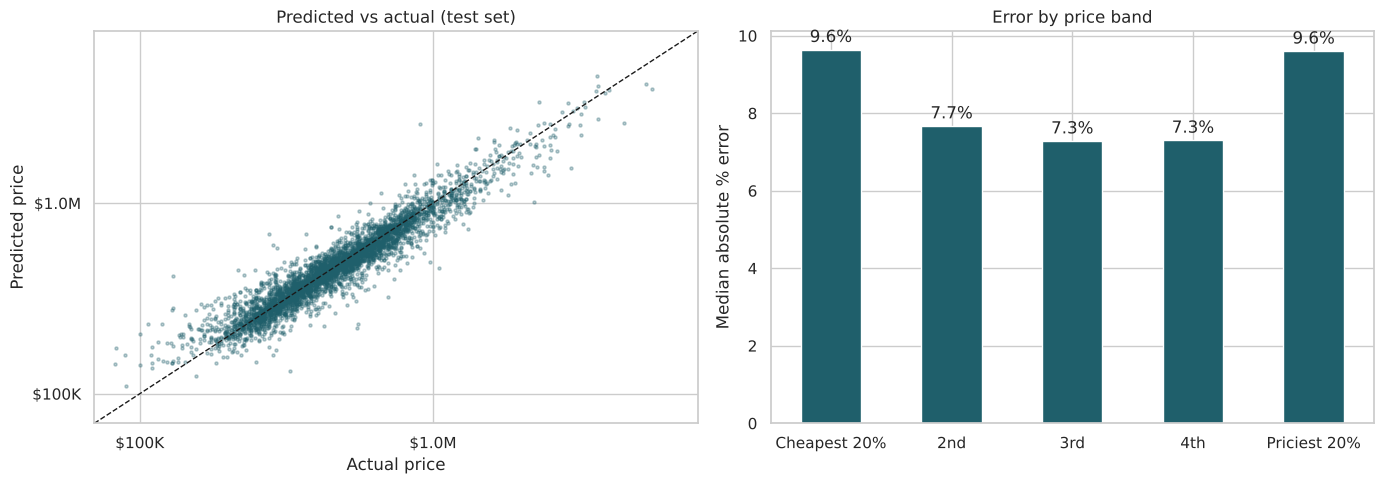

In [15]:
best = fitted[best_name]
pred = best.predict(X_test)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, pred, s=5, alpha=0.3, color=TEAL)
lims = [70_000, 8_000_000]
axes[0].plot(lims, lims, "k--", linewidth=1)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlim(lims); axes[0].set_ylim(lims)
axes[0].xaxis.set_major_formatter(dollars); axes[0].yaxis.set_major_formatter(dollars)
axes[0].set_xlabel("Actual price"); axes[0].set_ylabel("Predicted price")
axes[0].set_title("Predicted vs actual (test set)")

pct_err = (pred - y_test) / y_test * 100
bands = pd.qcut(y_test, 5, labels=["Cheapest 20%", "2nd", "3rd", "4th", "Priciest 20%"])
err_by_band = pd.Series(np.abs(pct_err)).groupby(bands.values, observed=True).median()
err_by_band.plot.bar(ax=axes[1], color=TEAL, rot=0)
axes[1].set_ylabel("Median absolute % error")
axes[1].set_title("Error by price band")
for i, v in enumerate(err_by_band):
    axes[1].text(i, v + 0.2, f"{v:.1f}%", ha="center")
plt.tight_layout()
plt.show()

### 5.3 Which features matter most?

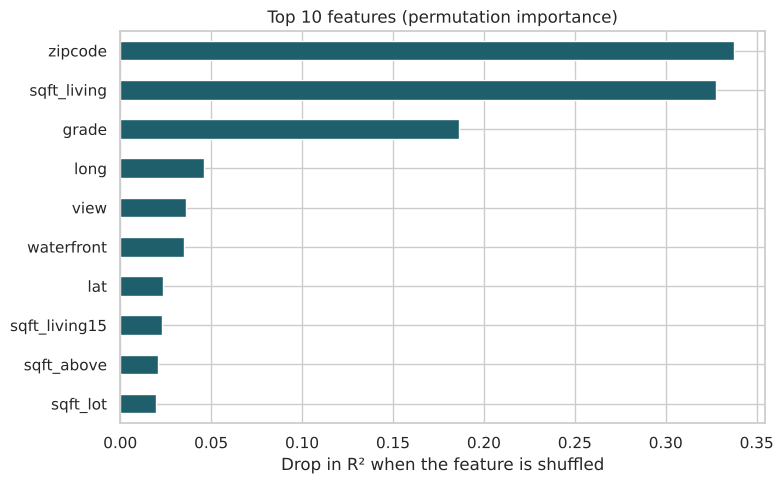

In [16]:
sub = X_test.sample(2000, random_state=RANDOM_STATE)
imp = permutation_importance(best, sub, y_test.loc[sub.index], n_repeats=5, random_state=RANDOM_STATE, scoring="r2")
importance = pd.Series(imp.importances_mean, index=sub.columns).sort_values().tail(10)
importance.plot.barh(figsize=(8, 5), color=TEAL)
plt.xlabel("Drop in R² when the feature is shuffled")
plt.title("Top 10 features (permutation importance)")
plt.tight_layout()
plt.savefig("images/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

Permutation importance measures how much accuracy drops when a feature's values are shuffled. Location (latitude, longitude and zipcode), living area and grade dominate, which matches the exploratory analysis.

## 6. Data for the Power BI dashboard

I export two clean tables for a Power BI dashboard: one row per sale, and one row per zipcode.

In [17]:
sales_out = df[["id", "date", "price", "price_per_sqft", "bedrooms", "bathrooms", "sqft_living", "grade",
                "condition", "waterfront", "view", "house_age", "renovated", "zipcode", "lat", "long"]]
sales_out.to_csv("powerbi_sales.csv", index=False)
zip_stats.reset_index().to_csv("powerbi_zipcodes.csv", index=False)
print("Saved powerbi_sales.csv and powerbi_zipcodes.csv")

Saved powerbi_sales.csv and powerbi_zipcodes.csv


## 7. Conclusions

1. **Location, size and build quality explain most of the price.** Price per square foot varies almost 4× across zipcodes; within a location, living area and grade do most of the work.
2. **Waterfront and view carry large premiums**, though waterfront homes are rare (under 1% of sales).
3. **Prices were flat between May 2014 and May 2015.** The data is too short to show a market trend.
4. **Getting the data representation right mattered more than the algorithm.** Treating zipcode as a category and modelling price and size on a log scale took the linear model from R² 0.70 to 0.87, and its typical error from 19% to 10%. Gradient boosting then improved it further, to 0.90 R² and a typical error of about 8%.
5. **Errors are larger for the most expensive homes**, where unique features (views, land, finishes) that the data doesn't capture matter more.

## 8. Recommendations

- **For pricing a home:** start from the zipcode's price per square foot, then adjust for grade, waterfront and view.
- **For an automated valuation tool:** the gradient-boosted model is accurate enough for a first estimate on typical homes, but high-end properties should be valued by an appraiser.
- **To improve the model:** add data the file lacks, such as school ratings, distance to downtown and transit, and recent nearby sales.

## 9. Limitations

- One county and 13 months of sales; the model should not be used for other areas or later years without retraining.
- Prices are not adjusted for inflation or market changes after 2015.
- 177 homes appear twice (resales), so a few homes may sit in both the training and test sets.